In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

In [2]:
PROJECT_ROOT = Path("..")

TRAIN_DIR = PROJECT_ROOT / "student_resource" / "dataset" / "train"
TEST_DIR = PROJECT_ROOT / "student_resource" / "dataset" / "test"

RESULTS_DIR = PROJECT_ROOT / "results" / "eda"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Train:", TRAIN_DIR)
print("Test :", TEST_DIR)

Train: ..\student_resource\dataset\train
Test : ..\student_resource\dataset\test


In [3]:
s1 = pd.read_csv(
    TRAIN_DIR / "train_source1.tsv",
    sep="\t"
)

s2 = pd.read_csv(
    TRAIN_DIR / "train_source2.tsv",
    sep="\t"
)

s3 = pd.read_csv(
    TRAIN_DIR / "train_source3.tsv",
    sep="\t"
)

gt = pd.read_csv(
    TRAIN_DIR / "train_ground_truth.tsv",
    sep="\t"
)

In [4]:
datasets = {
    "Source 1": s1,
    "Source 2": s2,
    "Source 3": s3,
    "Ground Truth": gt
}

for name, df in datasets.items():
    print(f"{name:15} : {df.shape}")

Source 1        : (2206821, 4)
Source 2        : (5034616, 4)
Source 3        : (5285603, 4)
Ground Truth    : (2206821, 2)


In [5]:
for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(name)
    print("="*50)
    print(df.columns.tolist())


Source 1
['entity_id', 'business_name', 'business_address', 'country']

Source 2
['entity_id', 'business_name', 'business_address', 'country']

Source 3
['entity_id', 'business_name', 'business_address', 'country']

Ground Truth
['source1_entity_id', 'matched_entity_ids']


In [6]:
display(s1.head(10))
display(s2.head(10))
display(s3.head(10))
display(gt.head(10))

,entity_id,business_name,business_address,country
0,S1-925783039,Orelee's Barbershop,"1795 Westchester Drive, High Point, NC",US
1,S1-773889195,Prime Money,"17560 Ellis Road, Tahlequah, OK",US
2,S1-377745466,B+ Retail Inc,"1712 Montebello Avenue, Phoenix, AZ",US
3,S1-133037285,Christ Chapel,"2100 Cameron Drive, Unit APARTMENT G, Dundalk, MD",US
4,S1-755362802,Prabhav Business Center,"797, Lake Town Block A, Kolkata, Howrah, West Bengal",India
5,S1-851869949,Custom Wealth Services LLC,"OH, Columbus, 5559 Orville Avenue",US
6,S1-785847572,Consulting Nyasa Nursing Private Limited,"2505, Tower 1, Oakwood, Runwal Greens, Mulund Goreagon Link Road, Near Fortis Hospital, Bhandup ...",India
7,S1-27541239,Nexus Anchor Rain,"1111 Church Street, Unit 2007, Nashville, TN",US
8,S1-629417405,Moore Bitwise Inc,"337 Oakland Avenue, Michigan City, IN",US
9,S1-22305073,Dermatology Green Medicine,"294 Meadowcreek Drive, Unit Unit 2, Village Of Pewaukee, WI",US


,entity_id,business_name,business_address,country
0,S2-166376419,राम मार्केटिंग प्राइवेट लिमिटेड,"KH NO. -570/13, NEW DELHI, WEST DELHI, Delhi",India
1,S2-764573417,-- Holloway Peak Inc Seafood,"105 ELM ST, MORGANTON, NC",US
2,S2-639257739,आदित्य प्रॉपर्टीज एलएलपी,"G-3/571, GULMOHAR COLONY, BHOPAL, Madhya Pradesh",India
3,S2-163963287,Summit Inc,"GREENSBORO, NC, 19 1/2 STARDUST TRAIL",US
4,S2-49942811,Delta Tetlecommunication Inc,"914 PIERPONT AVE, CLEVELAND, OH",US
5,S2-138046867,Lee and Lawson,"1702 Pine Avenue, CITY OF MENOMONIE, WI",US
6,S2-584977605,SHIVSHAKTI VIDYALAYA VIDYALAYA OVERSEAS CORPORATION | www.shivshakti.com,"H.NO 204 C ROAD HOSHIARPUR, PUNJAB, Punjab",India
7,S2-277444929,Shree Infracon Private Ltd,"63/2275/7, ALHIND TOWER, FIRST FLOOR, JAFFERKHAN COLONY, KOZHIKODE, Kerala",India
8,S2-721031885,Chavira Platinum Chimera LLC,"282 SAXONY DRIVE, FTT MITCHELL, KY",US
9,S2-508602797,FOUNDATION EXCEL AGENCY PRIVATE LIMITED,"HN 753 E-1, BHARAT NAGAR, 104/1/1 ERANDWANE, Maharashtra",India


,entity_id,business_name,business_address,country
0,S3-202863386,wilfordhancock.com,"Mack Rd, Haltom City, Texas",US
1,S3-859268022,International South Consultants Private Ltd,NaN,India
2,S3-22467283,LLC Moncada Léarning Center,"5780 Fawn Ct, Fort Worth, Texas",US
3,S3-671162755,Moyna's Coffee,"1 Ivanhoe Ave, PO Box 6009, Cincinnati, Ohio",US
4,S3-960981775,Pvt. EFS Print Ventures Ltd.,"Door No 183, 41St Cross, 22Nd Main 9Th Block Jayanagar, Bengaluru Urban, Bangalore, ಕರ್ನಾಟಕ",India
5,S3-578159284,LLC Hernandez Colonial Redwood,"2260- Housecreek Trail, Unit 407, Raleigh, North Carolina",US
6,S3-121412624,Classic Equity Partners Group,"6885 Catalpa Bluff Ln, PO Box 5799, Dickinson, Texas",US
7,S3-249416830,Ectolumdrex dba X+ Madison Inc,"S03575 Cty Tk M, Town Of Buffalo, WI",US
8,S3-107644605,Animal Hanisch Hospirlg,"##8 Willow Oak Lane, Fl. 0, Saint Louis, Missouri",US
9,S3-160217003,Gomez Optimal,"343 Hempstead 161, Hope, Arkansas",US


,source1_entity_id,matched_entity_ids
0,S1-965667,"S2-681193310,S2-743505751,S3-775321672,S3-11291185,S3-860443364"
1,S1-55344266,"S2-249013014,S2-197070651,S3-478195123,S3-384364074"
2,S1-343815751,"S2-790675320,S2-479876582,S3-878454467"
3,S1-656753428,"S2-153058913,S2-24659151,S3-679606215"
4,S1-102811957,"S2-478959098,S2-553508714,S2-625774905,S3-728090388,S3-928796641,S3-449308785"
5,S1-18727616,"S2-755677256,S3-187831601,S3-641489370,S3-476250621"
6,S1-318373630,"S2-660036492,S3-804600254"
7,S1-86989137,"S3-274817120,S3-312496301"
8,S1-29845983,"S2-648035184,S3-588502663"
9,S1-789009573,"S2-383871912,S3-74481402,S3-576451439"


In [7]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.dtypes)


Source 1
entity_id           str
business_name       str
business_address    str
country             str
dtype: object

Source 2
entity_id           str
business_name       str
business_address    str
country             str
dtype: object

Source 3
entity_id           str
business_name       str
business_address    str
country             str
dtype: object

Ground Truth
source1_entity_id     str
matched_entity_ids    str
dtype: object


In [8]:
for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(name)
    print("="*50)

    missing = df.isna().sum()
    missing_pct = (missing / len(df) * 100).round(2)

    missing_summary = pd.DataFrame({
        "missing_count": missing,
        "missing_percentage": missing_pct
    })

    display(missing_summary)


Source 1


,missing_count,missing_percentage
entity_id,0,0.0
business_name,0,0.0
business_address,0,0.0
country,0,0.0



Source 2


,missing_count,missing_percentage
entity_id,0,0.00
business_name,2,0.00
business_address,168967,3.36
country,0,0.00



Source 3


,missing_count,missing_percentage
entity_id,0,0.00
business_name,13,0.00
business_address,175916,3.33
country,0,0.00



Ground Truth


,missing_count,missing_percentage
source1_entity_id,0,0.00
matched_entity_ids,123247,5.58


In [9]:
for name, df in {
    "S1": s1,
    "S2": s2,
    "S3": s3
}.items():

    print(
        f"{name}:",
        df.duplicated().sum(),
        "complete duplicate rows"
    )

S1: 0 complete duplicate rows
S2: 0 complete duplicate rows
S3: 0 complete duplicate rows


In [10]:
for name, df in {
    "S1": s1,
    "S2": s2,
    "S3": s3
}.items():

    print(
        f"{name}:",
        df["entity_id"].duplicated().sum(),
        "duplicate entity IDs"
    )

S1: 0 duplicate entity IDs
S2: 0 duplicate entity IDs
S3: 0 duplicate entity IDs



S1


country
US       1323633
India     883188
Name: count, dtype: int64


S2


country
US       3016817
India    2017799
Name: count, dtype: int64


S3


country
US       3170056
India    2115547
Name: count, dtype: int64

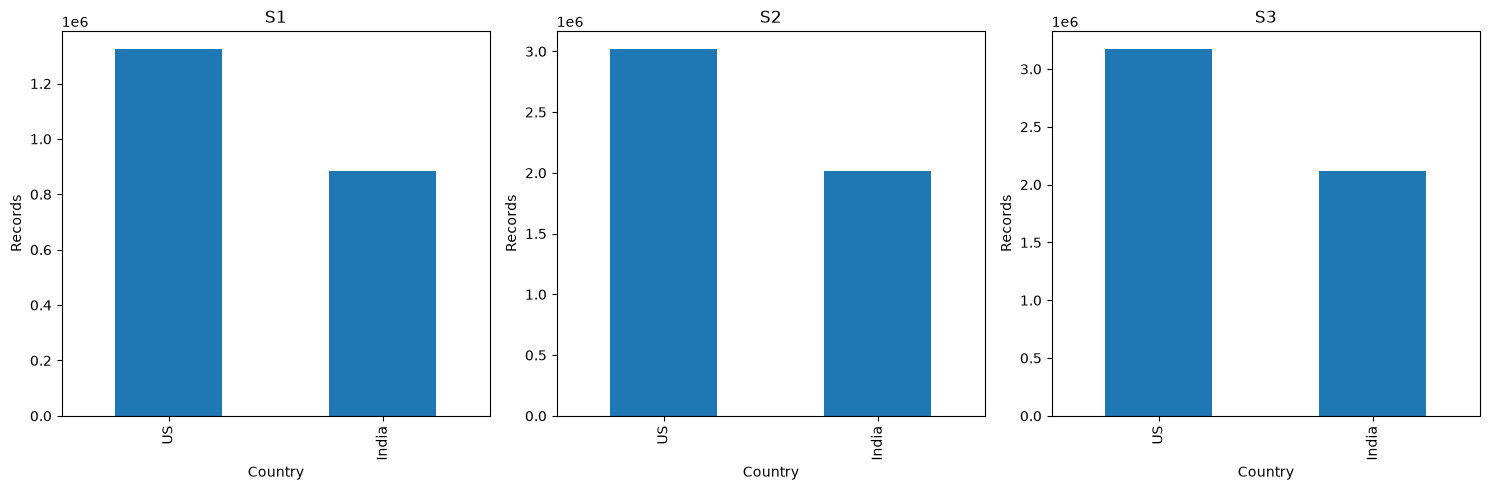

In [11]:
for name, df in {
    "S1": s1,
    "S2": s2,
    "S3": s3
}.items():

    print(f"\n{name}")
    display(df["country"].value_counts(dropna=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, df) in zip(
    axes,
    {
        "S1": s1,
        "S2": s2,
        "S3": s3
    }.items()
):
    df["country"].value_counts(dropna=False).plot(
        kind="bar",
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Country")
    ax.set_ylabel("Records")

plt.tight_layout()
plt.show()

count    2.206821e+06
mean     3.461253e+00
std      1.705323e+00
min      0.000000e+00
25%      2.000000e+00
50%      3.000000e+00
75%      5.000000e+00
max      1.100000e+01
Name: match_count, dtype: float64

match_count
0     123247
1     119157
2     375212
3     530841
4     484115
5     321957
6     164868
7      63968
8      18680
9       4205
10       534
11        37
Name: count, dtype: int64

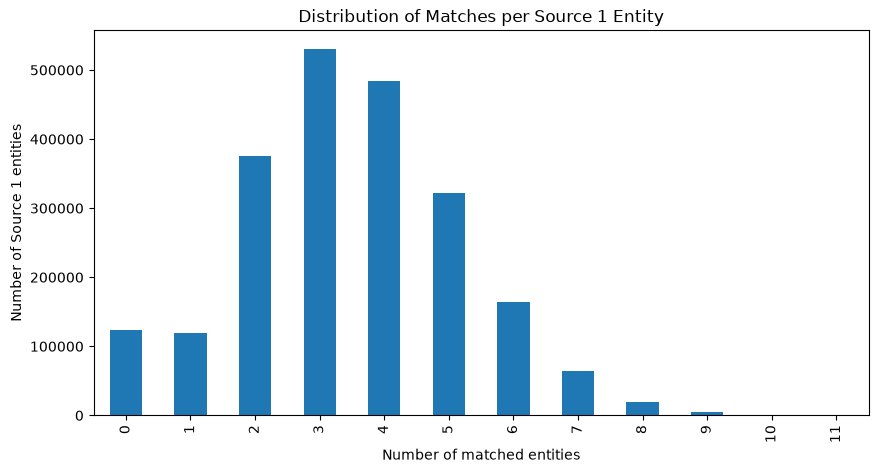

Singletons: 123247
Exactly one match: 119157
Multiple matches: 1964417


In [12]:
gt["matched_entity_ids"] = gt["matched_entity_ids"].fillna("").astype(str)

gt["match_count"] = gt["matched_entity_ids"].apply(
    lambda x: 0 if not x.strip() else len(x.split(","))
)

display(gt["match_count"].describe())

match_distribution = (
    gt["match_count"]
    .value_counts()
    .sort_index()
)

display(match_distribution)

plt.figure(figsize=(10, 5))

match_distribution.plot(kind="bar")

plt.xlabel("Number of matched entities")
plt.ylabel("Number of Source 1 entities")
plt.title("Distribution of Matches per Source 1 Entity")

plt.show()

print(
    "Singletons:",
    (gt["match_count"] == 0).sum()
)

print(
    "Exactly one match:",
    (gt["match_count"] == 1).sum()
)

print(
    "Multiple matches:",
    (gt["match_count"] > 1).sum()
)